# We load data from the Eurocrops dataset. First, I will chooose one region and year. 

In [1]:
#set working directory to project root
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

print(project_root)

/Users/henristaehelin/Desktop/UZH/SDS320/sds320/project


### 1. Data load. I chose to load data from italy in 2023. 

In [2]:
import geopandas as gpd
italy_2023 = gpd.read_parquet("../data/raw/vectors/raw_data/italy_2023.parquet")
italy_2023.head(5)

,cropfield,original_code,off_id,off_area,area_ha,geometry
0,945,1095,2987,1035,0.103386,"MULTIPOLYGON (((4492255.357 2281667.874, 44922..."
1,954,1095,3048,822,0.082144,"MULTIPOLYGON (((4490488.238 2281971.694, 44904..."
2,51241,1095,298948,2202,0.220087,"MULTIPOLYGON (((4453304.229 2280933.501, 44532..."
3,51356,2402,299382,552,0.055119,"MULTIPOLYGON (((4478577.375 2232224.952, 44785..."
4,51286,562,299229,25524,2.550201,"MULTIPOLYGON (((4496599.421 2242242.464, 44965..."


We have the cropfield number, the geometry, but what about the crop type label?

Could that be original_code?

In [3]:
import pandas as pd
crop_names = pd.read_csv("../data/raw/Eurocrops.csv")
crop_names.head(5)

,nuts,original_code,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
0,at,10001,NICHT DEFINIERT,not defined,3390000000,not_known_and_other,0,No specified use
1,at,105,KÖRNERMAIS,GRAIN CORN,3310106000,maize_corn_popcorn,6,Harvested as Grains
2,at,106,MAIS CORN-COB-MIX (CCM),CORN CORN-COB-MIX (CCM),3310106000,maize_corn_popcorn,0,No specified use
3,at,107,ZUCKERMAIS,SUGAR CORN,3310106000,maize_corn_popcorn,0,No specified use
4,at,109,SILOMAIS,SILO CORN,3310106000,maize_corn_popcorn,3,Fodder/Forage


This file has all the codes for each country. "nuts" is the country tag. So for italy it would be iti1. We want the table of country specific crop codes of only italy. 

In [4]:
italy_cropnames = crop_names[crop_names["nuts"] == "iti1"] #select only rows with italian codes
italy_cropnames.head(5)

,nuts,original_code,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
4132,iti1,1001,Avena,Oats,3310105000,oats,0,No specified use
4133,iti1,1002,Frumento duro,Durum wheat,3310102000,durum_hard_wheat,0,No specified use
4134,iti1,1003,Frumento tenero,Common soft wheat,3310101000,common_soft_wheat,0,No specified use
4135,iti1,1005,Mais,Corn,3310106000,maize_corn_popcorn,0,No specified use
4136,iti1,1007,Orzo,Barley,3310104000,barley,0,No specified use


Merge them with the italian crop dataset, now we will have the polygons with the labels. 
#### **Consider generalizing this process into a python script that we can call upon, this would allow us to efficiently combine multiple vector datasets from different countries into one.**

In [5]:
italy_crops = italy_2023.merge(
    italy_cropnames,
    on=["original_code"],
    how="left")
italy_crops.head(5)

,cropfield,original_code,off_id,off_area,area_ha,geometry,nuts,original_name,translated_name,hcat4_code,hcat4_name,usage_code,usage_name
0,945,1095,2987,1035,0.103386,"MULTIPOLYGON (((4492255.357 2281667.874, 44922...",iti1,Bosco,Woodland,3360000000,tree_wood_forest,0,No specified use
1,954,1095,3048,822,0.082144,"MULTIPOLYGON (((4490488.238 2281971.694, 44904...",iti1,Bosco,Woodland,3360000000,tree_wood_forest,0,No specified use
2,51241,1095,298948,2202,0.220087,"MULTIPOLYGON (((4453304.229 2280933.501, 44532...",iti1,Bosco,Woodland,3360000000,tree_wood_forest,0,No specified use
3,51356,2402,299382,552,0.055119,"MULTIPOLYGON (((4478577.375 2232224.952, 44785...",iti1,Oliva da trasformazione,Olive for processing,3330500000,olive,2,Industry/for processing
4,51286,562,299229,25524,2.550201,"MULTIPOLYGON (((4496599.421 2242242.464, 44965...",iti1,ERBA MEDICA,ALFAFA,3310202010,alfalfa_lucerne,0,No specified use


We now have polygons and labels. We will use hcat4_name as this is the harmonized label across multiple countries.

### 2. We want to combine it now with the Sentinel-2 raster data and load them together. 

In [6]:
italy_crops.crs
#first check CRS

<Projected CRS: EPSG:3035>
Name: ETRS89-extended / LAEA Europe
Axis Info [cartesian]:
- Y[north]: Northing (metre)
- X[east]: Easting (metre)
Area of Use:
- name: Europe - European Union (EU) countries and candidates. Europe - onshore and offshore: Albania; Andorra; Austria; Belgium; Bosnia and Herzegovina; Bulgaria; Croatia; Cyprus; Czechia; Denmark; Estonia; Faroe Islands; Finland; France; Germany; Gibraltar; Greece; Hungary; Iceland; Ireland; Italy; Kosovo; Latvia; Liechtenstein; Lithuania; Luxembourg; Malta; Monaco; Montenegro; Netherlands; North Macedonia; Norway including Svalbard and Jan Mayen; Poland; Portugal including Madeira and Azores; Romania; San Marino; Serbia; Slovakia; Slovenia; Spain including Canary Islands; Sweden; Switzerland; Türkiye (Turkey); United Kingdom (UK) including Channel Islands and Isle of Man; Vatican City State.
- bounds: (-35.58, 24.6, 44.83, 84.73)
Coordinate Operation:
- name: Europe Equal Area 2001
- method: Lambert Azimuthal Equal Area
Datum: Eur

In [7]:
#Our vector data crs is EPSG:3035, we want to get EPSG:4326 as this will be our raster CRS Let's convert. 
italy_crops = italy_crops.to_crs("EPSG:4326")

Getting the Sentinel 2 data.
#### **Again this whole process could also be pythonscriptified. Since its pretty straightforward.**

In [8]:
#1. We need to define a study area, 

italy_projected = italy_crops.to_crs("EPSG:32632")

center_field = italy_projected.iloc[24] #makes the field in the 24th row the center field. 

distances = italy_projected.geometry.centroid.distance(
    center_field.geometry.centroid
) #calculates distances of all fields to the center field

italy_subset = italy_crops.loc[distances[distances < 2000].index] #only chooses fields whose distances are below 2000
italy_subset.head(5)

geometry = italy_subset.geometry.iloc[0].__geo_interface__

Get the bounding box for our study area.

In [9]:
bbox_wgs84 = list(italy_subset.total_bounds)

print(bbox_wgs84)

[np.float64(11.765161610233221), np.float64(43.302263709644606), np.float64(11.815881971591654), np.float64(43.33881893928715)]


In [10]:
from pystac_client import Client
import planetary_computer as pc

pc_catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1")

search = pc_catalog.search(
    collections=["sentinel-2-l2a"],
    intersects=geometry,
    datetime="2023-01-01/2023-12-31",
    query={"eo:cloud_cover": {"lt": 20}},
    max_items=10,
)

items = list(search.items())
print(f"Found {len(items)} Sentinel-2 item(s)")

Found 10 Sentinel-2 item(s)


In [11]:
items_sorted = sorted(
    items,
    key=lambda item: item.properties.get("eo:cloud_cover", 999),
)

s2_item = pc.sign(items_sorted[0]) #this is now signed to STAC so I can access it 

print("Selected item:", s2_item.id)
print("Date:", s2_item.datetime)
print("Cloud cover:", round(s2_item.properties.get("eo:cloud_cover"), 2))

print("\nUseful assets:")
for key in ["B02", "B03", "B04", "B08", "SCL", "visual"]:
    if key in s2_item.assets:
        print(key, "-", s2_item.assets[key].title)

Selected item: S2A_MSIL2A_20231219T101431_R022_T32TQP_20231220T125611
Date: 2023-12-19 10:14:31.024000+00:00
Cloud cover: 0.0

Useful assets:
B02 - Band 2 - Blue - 10m
B03 - Band 3 - Green - 10m
B04 - Band 4 - Red - 10m
B08 - Band 8 - NIR - 10m
SCL - Scene classfication map (SCL)
visual - True color image


In [12]:
from scripts.Raster_helper_functions import save_multiband_subset

s2_path = save_multiband_subset(
    item=s2_item,
    asset_keys=[
        "B02", #Blue
        "B03", #Green
        "B04", #Red
        "B08", #NIR
    ],
    bbox_wgs84=bbox_wgs84,
    output_path="../data/raw/imagery/sentinel2/italy_po_valley_0.tif",
)

Saved: ../data/raw/imagery/sentinel2/italy_po_valley_0.tif (0.99 MB)


In [13]:
import leafmap

m1 = leafmap.Map(height="500px")

m1.add_basemap("Esri.WorldImagery") #basemap

m1.add_raster(
    str(s2_path), #s2path is where our GeoTIFF file is located. We read that and then add it to our basemap. 
    indexes=[3,2,1], #this is a regular RGB image. True color composite
    layer_name="Sentinel-2 True Color"
)
m1.add_raster(
    str(s2_path),
    indexes=[4,3,2], #this is a false color image using the NIR band for red and getting rid of blue.
    layer_name ="Sentinel-2 False Color"  
)

m1.add_gdf(
    italy_subset,
    layer_name="Crop Fields"
)

m1.add_layer_control()
m1

Map(center=[43.320530500000004, 11.790539500000001], controls=(ZoomControl(options=['position', 'zoom_in_text'…

## 3. Data Preprocessing

While we can visually confirm that the polygons match up onto the satellite data. We want to check crs of both vector and raster data to make sure they are the same. Also we can check the bounds while we are at it.

In [14]:
import rasterio

with rasterio.open(s2_item.assets["B04"].href) as src:
    raster_crs = src.crs
    raster_bounds = src.bounds
    raster_extent = box(*raster_bounds)

print("Raster CRS:", raster_crs)
print("Vector CRS:", italy_subset.crs)
print("Raster bounds:", raster_bounds)
print("Vector bounds:", italy_subset.total_bounds)
print("Raster Extent:", raster_extent)


NameError: name 'box' is not defined

#### See! They weren't actually the same CRS, we need to correct. Also the bounds are not the same. 

In [15]:
italy_subset = italy_subset.to_crs("EPSG:32632")
print("Vector CRS:", italy_subset.crs)

Vector CRS: EPSG:32632


Now lets map again real quick for another check.

In [16]:

import leafmap

m1 = leafmap.Map(height="300px")

m1.add_basemap("Esri.WorldImagery") #basemap

m1.add_raster(
    str(s2_path), #s2path is where our GeoTIFF file is located. We read that and then add it to our basemap. 
    indexes=[3,2,1], #this is a regular RGB image. True color composite
    layer_name="Sentinel-2 True Color"
)
m1.add_raster(
    str(s2_path),
    indexes=[4,3,2], #this is a false color image using the NIR band for red and getting rid of blue.
    layer_name ="Sentinel-2 False Color"  
)

m1.add_gdf(
    italy_subset,
    layer_name="Crop Fields"
)

m1.add_layer_control()
m1

Map(center=[43.320530500000004, 11.790539500000001], controls=(ZoomControl(options=['position', 'zoom_in_text'…

Its good. However some of the vector polygons are outside of the raster image. We want only the ones that are fully within, but also don't want the ones that are half out to be treated as background, the model should only train on labelled areas. 

In [17]:
#We filter to keep only the polygons ones within the raster extent
inside = italy_subset.geometry.within(raster_extent)
italy_inside = italy_subset.loc[inside].copy()

print("Features fully inside image:", len(italy_inside))
print("Features touching or crossing image boundary:", len(italy_subset) - len(italy_inside))

NameError: name 'raster_extent' is not defined

This is odd, i can clearly see that there are polygons covering the image boundary, but the code can't identify them. The crs is the same, perhaps its the fact that the bounds are different? I thought that was what I was correcting for though. 

## 4. Converting vector data in a raster mask. 

First we need to define an output path so that our rasterised vector data is a clear place. 

In [18]:
from pathlib import Path

import geoai

output_path = Path("../data/raw/raster/italy_mask.tif")
output_path

PosixPath('../data/raw/raster/italy_mask.tif')

In [28]:
geoai.vector_to_raster(
    italy_subset,
    output_path,
    reference_raster=s2_path,
    attribute_field = "hcat4_code"
)

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(420, 398), dtype=uint8)

In [29]:
import rasterio

with rasterio.open(output_path) as src:
    print("CRS:", src.crs)
    print("Size:", src.width, "x", src.height)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("Bands:", src.count)
    print("Dtype:", src.dtypes)

CRS: EPSG:32632
Size: 398 x 420
Resolution: (10.0, 10.0)
Bounds: BoundingBox(left=724281.117947395, bottom=4798092.331510197, right=728261.117947395, top=4802292.331510197)
Bands: 1
Dtype: ('uint8',)


In [30]:
import numpy as np

with rasterio.open(output_path) as src:
    mask = src.read(1)

print("Shape:", mask.shape)
print("Unique values:", np.unique(mask))

Shape: (420, 398)
Unique values: [  0 255]


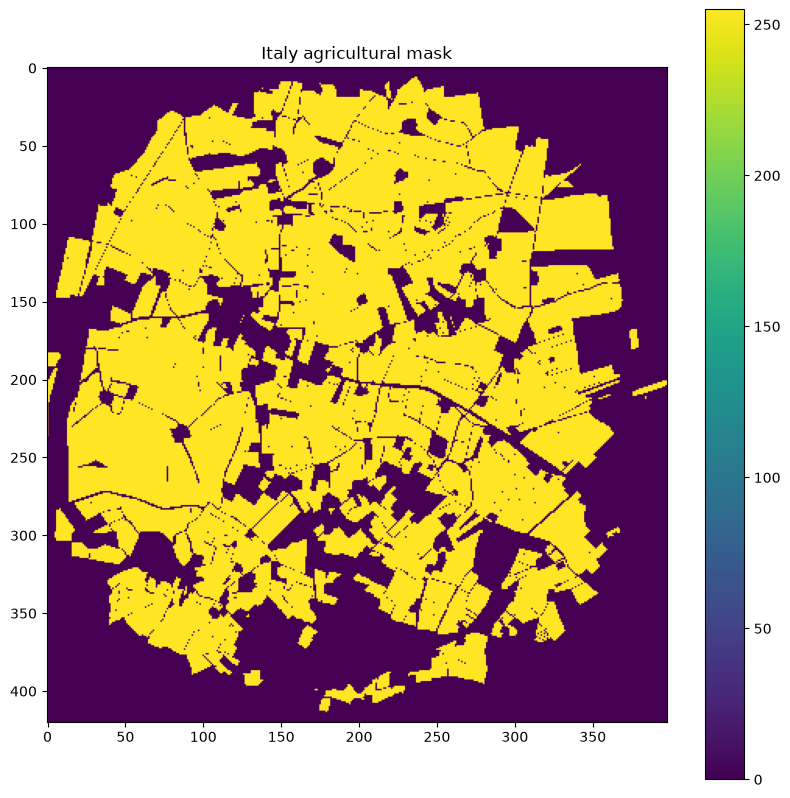

In [31]:
import matplotlib.pyplot as plt
import rasterio

with rasterio.open(output_path) as src:
    mask = src.read(1)

plt.figure(figsize=(10, 10))
plt.imshow(mask)
plt.colorbar()
plt.title("Italy agricultural mask")
plt.show()

In [32]:
with rasterio.open(s2_path) as src:
    print("S2:", src.width, src.height, src.crs, src.res)

with rasterio.open(output_path) as src:
    print("Mask:", src.width, src.height, src.crs, src.res)

S2: 398 420 EPSG:32632 (10.0, 10.0)
Mask: 398 420 EPSG:32632 (10.0, 10.0)


#### The mask is binary it has values that show a crop field (1) and those that are not crop fields (0).
it also looks like it clipped it so the polygons that were a bit outside the raster are now clipped. Maybe this is fine for the analysis.

In [35]:
print(italy_subset["hcat4_code"].value_counts())

hcat4_code
3330500000    155
3310000000    109
3310102000    108
3330600000     86
3370000000     69
3310101000     67
3310202010     51
3310104000     45
3310604020     20
3390000000     20
3310201010     18
3320100000     15
3320201000      9
3360000000      9
3310106000      7
3330102000      5
3310700000      5
3310201040      4
3310202030      4
3310714000      4
3310604010      4
3311200000      3
3310708020      2
3340200000      2
3369900000      2
3310201070      2
3310707010      1
3310800000      1
3310810000      1
3310715040      1
3310703030      1
3310105000      1
3310202060      1
3310702030      1
3350000000      1
Name: count, dtype: int64


In [36]:
print(italy_subset["hcat4_code"].dtype)

int64
